In [48]:
import pandas as pd

# read the parquet file
df = pd.read_parquet("../data/clean/studies_subset_t1.parquet")
df

,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,Space Program,Project Type,Study Public Release Date
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,NaN,Ground Study,1513728000.0
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1596153600.0
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1590883200.0
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),NASA,Spaceflight Study,1522368000.0
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1589500800.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),NASA; NIH,Ground Study,1709769600.0
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,NaN,Spaceflight Study,1715644800.0
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),NASA,Spaceflight Study,1690848000.0
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,NASA,Spaceflight Study,1450137600.0


## Remove duplicate studies

In [49]:
# check for duplicate accessions
dupes = df[df["Accession"].duplicated(keep=False)]
print("duplicate accessions:", dupes["Accession"].unique().tolist())

# OSD-729 is in the OSDR search index twice, only the release date differs
# -> keep the row with the latest release date
df = (df.assign(_date=df["Study Public Release Date"].astype(float))
        .sort_values("_date")
        .drop_duplicates("Accession", keep="last")
        .drop(columns="_date")
        .sort_index())
assert df["Accession"].is_unique
print("rows after dropping duplicates:", len(df))


duplicate accessions: ['OSD-729']
rows after dropping duplicates: 576


## Cleanup organisms column

In [50]:
# print organism types and their counts
organism_counts = df["organism"].value_counts()
print(organism_counts)

organism
Mus musculus                            210
Homo sapiens                            112
Arabidopsis thaliana                     62
Microbiota                               42
Drosophila melanogaster                  14
                                       ... 
Brachypodium distachyon                   1
Not Applicable     Microbiota             1
Not Applicable     Bacillus subtilis      1
Mus musculus     Microbiota               1
Burkholderia contaminans                  1
Name: count, Length: 83, dtype: int64


In [51]:
import re

PLACEHOLDERS = {"Not Applicable", "not applicable", "N/A", ""}

def split_organisms(value):
    if pd.isna(value):
        return []
    parts = [p.strip() for p in re.split(r"\s{2,}", str(value))]
    return sorted({p for p in parts if p not in PLACEHOLDERS})

df["organism_list"] = df["organism"].map(split_organisms)
df["n_organisms"] = df["organism_list"].str.len()

# counts per individual organism (a study with 3 organisms counts for each)
org_counts = df["organism_list"].explode().value_counts()
print(org_counts.head(20))

# audit numbers
print("studies with no organism after cleaning:", (df["n_organisms"] == 0).sum())
print("studies with >1 organism:", (df["n_organisms"] > 1).sum())
print("contained 'Not Applicable':",
      df["organism"].astype("string").str.contains("Not Applicable", na=False).sum())

organism_list
Mus musculus                    216
Homo sapiens                    116
Arabidopsis thaliana             62
Microbiota                       48
Rattus norvegicus                15
Drosophila melanogaster          14
Caenorhabditis elegans            9
Bacillus subtilis                 6
Saccharomyces cerevisiae          6
Escherichia coli                  6
Staphylococcus aureus             5
Staphylococcus saprophyticus      4
Danio rerio                       4
Klebsiella quasipneumoniae        3
Fusarium oxysporum                3
Aspergillus niger                 3
Burkholderia contaminans          3
Bacillus pumilus                  3
cellular organisms                3
Euprymna scolopes                 3
Name: count, dtype: int64
studies with no organism after cleaning: 4
studies with >1 organism: 26
contained 'Not Applicable': 12


In [52]:
GROUPS = {
    "Mus musculus": "Mouse", "Rattus norvegicus": "Rat", "Homo sapiens": "Human",
    "Arabidopsis thaliana": "Plant", "Brassica rapa": "Plant", "Triticum aestivum": "Plant",
    "Solanum lycopersicum": "Plant", "Brachypodium distachyon": "Plant",
    "Drosophila melanogaster": "Invertebrate", "Caenorhabditis elegans": "Invertebrate",
    "Danio rerio": "Fish", "Oryzias latipes": "Fish",
    "Saccharomyces cerevisiae": "Fungi", "Microbiota": "Microbial community",
}

def organism_group(orgs):
    groups = {GROUPS.get(o, "Other microbes/other") for o in orgs}
    return sorted(groups) if groups else ["Unknown"]

df["organism_group"] = df["organism_list"].map(organism_group)
print(df["organism_group"].explode().value_counts())
df

organism_group
Mouse                   216
Human                   116
Other microbes/other     84
Plant                    66
Microbial community      48
Invertebrate             23
Rat                      15
Fungi                     6
Fish                      6
Unknown                   4
Name: count, dtype: int64


,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,Space Program,Project Type,Study Public Release Date,organism_list,n_organisms,organism_group
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,NaN,Ground Study,1513728000.0,"[Acinetobacter radioresistens, Aranicola prote...",4,[Other microbes/other]
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1596153600.0,"[Enterobacter bugandensis, Kalamiella piersoni...",4,[Other microbes/other]
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1590883200.0,"[Enterobacter bugandensis, Klebsiella quasipne...",3,[Other microbes/other]
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),NASA,Spaceflight Study,1522368000.0,[Fusarium oxysporum],1,[Other microbes/other]
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1589500800.0,[Rhodotorula mucilaginosa],1,[Other microbes/other]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),NASA; NIH,Ground Study,1709769600.0,[Homo sapiens],1,[Human]
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,NaN,Spaceflight Study,1715644800.0,[Homo sapiens],1,[Human]
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),NASA,Spaceflight Study,1690848000.0,[Mus musculus],1,[Mouse]
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,NASA,Spaceflight Study,1450137600.0,[Mus musculus],1,[Mouse]


In [53]:
# show columns with unkonwn organism_group

df[df["organism_group"].apply(lambda x: "Unknown" in x)]

,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,Space Program,Project Type,Study Public Release Date,organism_list,n_organisms,organism_group
65,Because of their ubiquity and resistance to sp...,"Bacillus subtilis spores, PROTECT experiment, ...",OSD-28,NaN,NaN,transcription profiling,DNA microarray,environment exposure gravitation,STS-122 STS-128,International Space Station (ISS),ESA,Spaceflight Study,0,[],0,[Unknown]
314,Worms spun at higher than normal g values for ...,Worms spun in centrifuge at elevated g values,OSD-190,NaN,NaN,transcription profiling,DNA microarray,Altered Gravity,NaN,NaN,NaN,Ground Study,1371859200.0,[],0,[Unknown]
335,Presented here is the environmental microbiome...,Microbial Observatory (ISS-MO): Indoor microbi...,OSD-69,NaN,NaN,Metagenomic sequencing,Whole-Genome Shotgun Sequencing,Spaceflight Treatment,ISS Increments 42,International space station (ISS),NASA,Spaceflight Study,1467849600.0,[],0,[Unknown]
427,We differentiated mouse bone marrow cells in t...,Evaluation of in vitro macrophage differentiat...,OSD-50,NaN,NaN,transcription profiling,DNA microarray,Spaceflight,STS-126,Space Transportation System (STS),NASA,Spaceflight Study,1458518400.0,[],0,[Unknown]


In [54]:
# manually add organism data to those columns
MANUAL_ORGANISMS = {
    "OSD-28":  (["Bacillus subtilis"],      "manual: from description"),
    "OSD-190": (["Caenorhabditis elegans"], "manual: inferred ('worms', mixed-stage cultures)"),
    "OSD-69":  (["Microbiota"],             "manual: environmental ISS microbiome"),
    "OSD-50":  (["Mus musculus"],           "manual: from description"),
}

df["organism_source"] = "OSDR metadata"
for acc, (orgs, note) in MANUAL_ORGANISMS.items():
    idx = df.index[df["Accession"] == acc]
    assert len(idx) == 1, f"{acc}: found {len(idx)} rows"
    df.at[idx[0], "organism_list"] = orgs
    df.at[idx[0], "organism_source"] = note

df["n_organisms"] = df["organism_list"].str.len()
df["organism_group"] = df["organism_list"].map(organism_group)
print("remaining Unknown:", df["organism_group"].map(lambda g: "Unknown" in g).sum())
df

remaining Unknown: 0


,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,Space Program,Project Type,Study Public Release Date,organism_list,n_organisms,organism_group,organism_source
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,NaN,Ground Study,1513728000.0,"[Acinetobacter radioresistens, Aranicola prote...",4,[Other microbes/other],OSDR metadata
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1596153600.0,"[Enterobacter bugandensis, Kalamiella piersoni...",4,[Other microbes/other],OSDR metadata
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1590883200.0,"[Enterobacter bugandensis, Klebsiella quasipne...",3,[Other microbes/other],OSDR metadata
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),NASA,Spaceflight Study,1522368000.0,[Fusarium oxysporum],1,[Other microbes/other],OSDR metadata
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1589500800.0,[Rhodotorula mucilaginosa],1,[Other microbes/other],OSDR metadata
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),NASA; NIH,Ground Study,1709769600.0,[Homo sapiens],1,[Human],OSDR metadata
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,NaN,Spaceflight Study,1715644800.0,[Homo sapiens],1,[Human],OSDR metadata
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),NASA,Spaceflight Study,1690848000.0,[Mus musculus],1,[Mouse],OSDR metadata
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,NASA,Spaceflight Study,1450137600.0,[Mus musculus],1,[Mouse],OSDR metadata


## Cleanup Space Program column

In [55]:
df["Space Program"].value_counts()

Space Program
NASA                                                               294
JAXA                                                                23
ESA                                                                 19
German Aerospace Center (DLR)                                        5
NASA, NIH                                                            4
ESA, NASA                                                            3
Italian Space Agency (ASI)                                           3
Japan Aerospace Exploration Agency (JAXA)                            2
Spanish Space Program                                                2
NASA, NSBRI                                                          2
NASA, ESA                                                            2
German Aerospace Center DLR                                          1
NASA, JAXA, Roscosmos                                                1
Japan Aerospace Exploration Agency                             

In [56]:
import re

SEP = r",|;|\band\b"

def split_multi(value, sep=SEP):
    if pd.isna(value):
        return []
    parts = [re.sub(r"^the\s+", "", p.strip(), flags=re.I) for p in re.split(sep, str(value))]
    return [p for p in parts if p and p.lower() not in {"not applicable", "n/a"}]

# raw spelling -> space agency, anything not in here gets skipped
PROGRAM_MAP = {
    "NASA": "NASA",
    "ESA": "ESA", "European Space Agency (ESA)": "ESA",
    "JAXA": "JAXA", "Japan Aerospace Exploration Agency": "JAXA",
    "Japan Aerospace Exploration Agency (JAXA)": "JAXA",
    "German Aerospace Center (DLR)": "DLR", "German Aerospace Center DLR": "DLR",
    "Italian Space Agency (ASI)": "ASI",
    "French National Space Agency": "CNES", "CNES": "CNES",
    "CSA": "CSA",
    "Russian Space Agency": "Roscosmos", "Russian Federal Space Agency": "Roscosmos",
    "Roscosmos": "Roscosmos",
    "ISRO": "ISRO",
    "UK Space Agency": "UKSA",
    "Swedish National Space Agency": "SNSA",
    "Spanish Space Program": "Spain",
}

def clean_programs(value):
    agencies, skipped = [], []
    for p in split_multi(value):
        if p in PROGRAM_MAP:
            agencies.append(PROGRAM_MAP[p])
        else:
            skipped.append(p)
    return sorted(set(agencies)), skipped

res = df["Space Program"].map(clean_programs)
df["space_agencies"] = res.str[0]

# everything that got skipped, check that no space agency is in here
print("skipped:\n", res.str[1].explode().dropna().value_counts())
print(df["space_agencies"].explode().value_counts())


skipped:
 Space Program
NIH                                                            7
NSBRI                                                          2
NSF                                                            2
ESRANGE (European Space                                        1
Sounding Rocket Range) Space Center                            1
DoD Space Test Program                                         1
FSA                                                            1
NIAID                                                          1
Boeing                                                         1
Space Transportation System (Shuttle)                          1
International Space Station (ISS)                              1
CASS                                                           1
NRF                                                            1
KHIDI                                                          1
Coordenação de Aperfeiçoamento de Pessoal de Nível Superior    1
D

In [57]:
# print all rows where there is a value in "Flight Program" but not in "Space Program"
df[(df["Flight Program"].notna()) & (df["Space Program"].isna())]

,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,Space Program,Project Type,Study Public Release Date,organism_list,n_organisms,organism_group,organism_source,space_agencies
59,A comprehensive analysis of both the molecular...,Space flight alters bacterial gene expression ...,OSD-11,Salmonella enterica,Cells,transcription profiling,DNA microarray,Spaceflight,STS-115,Shuttle Program,NaN,Spaceflight Study,1189641600.0,[Salmonella enterica],1,[Other microbes/other],OSDR metadata,[]
111,Immune dysregulation is among the main adverse...,Plasticity of the human IgM repertoire in resp...,OSD-316,Homo sapiens,Whole blood,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Study Subject Time,NaN,International Space Station (ISS),NaN,Spaceflight Study,1590451200.0,[Homo sapiens],1,[Human],OSDR metadata,[]
154,The vestibular system receives a permanent inf...,Adaptive changes in the vestibular system of l...,OSD-192,Helix lucorum,statocyst,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Light Cycle Food Deprivati...,Bion_M1,Bion-M1 biosatellite,NaN,Spaceflight Study,1509494400.0,[Helix lucorum],1,[Other microbes/other],OSDR metadata,[]
185,Microarray Analysis of Space-flown Murine Thym...,Microarray Analysis of Space-flown Murine Thym...,OSD-4,Mus musculus,thymus,transcription profiling,DNA microarray,Spaceflight,NaN,Space Transportation System (Shuttle),NaN,Spaceflight Study,1268179200.0,[Mus musculus],1,[Mouse],OSDR metadata,[]
361,"Upon weightlessness and microgravity, deleteri...",Mouse muscle LC-MSMS upon weightlessness,OSD-139,Mus musculus,Vastus lateralis Left soleus Left exte...,protein expression profiling,mass spectrometry,Spaceflight Tissue,NaN,BION-M1 biosatellite,NaN,Spaceflight Study,1497398400.0,[Mus musculus],1,[Mouse],OSDR metadata,[]
374,The cardiovascular system is strongly impacted...,Spaceflight effects on human vascular smooth m...,OSD-635,Homo sapiens,Cells,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight,SpaceX-17,International Space Station (ISS),NaN,Spaceflight Study,1712102400.0,[Homo sapiens],1,[Human],OSDR metadata,[]
406,Spaceflight provides a unique environment to s...,Spaceflight reshapes Alzheimer's disease–assoc...,OSD-941,Homo sapiens,"Cells, Cultured",transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Genotype Disease Condition,SpaceX-30,International Space Station (ISS),NaN,Spaceflight Study,1792972800.0,[Homo sapiens],1,[Human],OSDR metadata,[]
455,The development of eye pathology is a serious ...,Artificial Gravity Attenuates the Transcriptom...,OSD-758,Mus musculus,Right retina,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Altered Gravity,SpaceX-27,International Space Station (ISS),NaN,Spaceflight Study,1730851200.0,[Mus musculus],1,[Mouse],OSDR metadata,[]
470,The development of eye pathology is a serious ...,Artificial Gravity Attenuates the Transcriptom...,OSD-759,Mus musculus,Right optic nerve,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Altered Gravity,SpaceX-27,International Space Station (ISS),NaN,Spaceflight Study,1730851200.0,[Mus musculus],1,[Mouse],OSDR metadata,[]
511,"As human space exploration accelerates, unders...",MicroRNAs shape mouse age-independent tissue a...,OSD-913,Mus musculus,Kidney,transcription profiling,miRNA Sequencing,Spaceflight Age Euthanasia Location ...,SpaceX-16,International Space Station (ISS),NaN,Spaceflight Study,1770854400.0,[Mus musculus],1,[Mouse],OSDR metadata,[]


In [58]:
# Manually add space program data to those columns
MANUAL_PROGRAMS = {
    "OSD-11":   (["NASA"], "manual: infered from flight program"),
    "OSD-316":  (["NASA"], "manual: infered from flight program"),
    "OSD-192":  (["Roscosmos"], "manual: infered from flight program"),
    "OSD-4":    (["NASA"], "manual: infered from flight program"),
    "OSD-139":  (["Roscosmos"], "manual: infered from flight program"),
    "OSD-635":  (["NASA"], "manual: infered from flight program"),
    "OSD-941":  (["NASA"], "manual: infered from flight program"),
    "OSD-758":  (["NASA"], "manual: infered from flight program"),
    "OSD-759":  (["NASA"], "manual: infered from flight program"),
    "OSD-913":  (["NASA"], "manual: infered from flight program"),
    "OSD-323":  (["NASA"], "manual: space and flight program are swapped"),
}

df["space_program_source"] = "OSDR metadata"
for acc, (agencies, note) in MANUAL_PROGRAMS.items():
    idx = df.index[df["Accession"] == acc]
    assert len(idx) == 1, f"{acc}: found {len(idx)} rows"
    df.at[idx[0], "space_agencies"] = agencies
    df.at[idx[0], "space_program_source"] = note

df["n_space_agencies"] = df["space_agencies"].str.len()
print("studies with no space agency:", (df["n_space_agencies"] == 0).sum())
print("studies with >1 space agency:", (df["n_space_agencies"] > 1).sum())
df


studies with no space agency: 188
studies with >1 space agency: 11


,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,Space Program,Project Type,Study Public Release Date,organism_list,n_organisms,organism_group,organism_source,space_agencies,space_program_source,n_space_agencies
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,NaN,Ground Study,1513728000.0,"[Acinetobacter radioresistens, Aranicola prote...",4,[Other microbes/other],OSDR metadata,[],OSDR metadata,0
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1596153600.0,"[Enterobacter bugandensis, Kalamiella piersoni...",4,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1590883200.0,"[Enterobacter bugandensis, Klebsiella quasipne...",3,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),NASA,Spaceflight Study,1522368000.0,[Fusarium oxysporum],1,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),NASA,Spaceflight Study,1589500800.0,[Rhodotorula mucilaginosa],1,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),NASA; NIH,Ground Study,1709769600.0,[Homo sapiens],1,[Human],OSDR metadata,[NASA],OSDR metadata,1
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,NaN,Spaceflight Study,1715644800.0,[Homo sapiens],1,[Human],OSDR metadata,[],OSDR metadata,0
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),NASA,Spaceflight Study,1690848000.0,[Mus musculus],1,[Mouse],OSDR metadata,[NASA],OSDR metadata,1
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,NASA,Spaceflight Study,1450137600.0,[Mus musculus],1,[Mouse],OSDR metadata,[NASA],OSDR metadata,1


## Cleanup Flight Program column

In [59]:
df["Flight Program"].value_counts()

Flight Program
International Space Station (ISS)                                             234
Space Transportation System (STS)                                              17
Internation Space Station (ISS)                                                10
Rodent Research (RR)                                                            5
ISS                                                                             4
Space Transportation System (Shuttle)                                           3
BION-M1 biosatellite                                                            3
NASA Airborne Science Program                                                   2
International Space Station                                                     2
ISS National Laboratory                                                         2
Soyuz                                                                           1
Shuttle Program                                                                 1
S

In [60]:
# raw spelling -> flight platform, anything not in here gets skipped
FLIGHT_MAP = {
    # ISS (incl. misspellings)
    "International Space Station (ISS)": "ISS", "International Space Station": "ISS",
    "International space station (ISS)": "ISS", "Internation Space Station (ISS)": "ISS",
    "International Space Staion (ISS)": "ISS", "ISS": "ISS",
    "ISS National Laboratory": "ISS",
    "Rodent Research (RR)": "ISS",  # rodent research missions fly on the ISS
    # space shuttle
    "Space Transportation System (STS)": "Space Shuttle", "Space Transporation System (STS)": "Space Shuttle",
    "Space Transportation System (Shuttle)": "Space Shuttle", "Space Shuttle": "Space Shuttle",
    "Shuttle Program": "Space Shuttle", "STS-131": "Space Shuttle",
    # russian capsules / satellites
    "BION-M1 biosatellite": "Bion-M1", "Bion-M1 biosatellite": "Bion-M1",
    "Foton-M4 satellite": "Foton-M4",
    "Soyuz": "Soyuz",
    # suborbital / parabolic
    "TEXUS-49": "TEXUS sounding rocket", "TEXUS-51": "TEXUS sounding rocket",
    "Virgin Galactic SpaceShipTwo": "SpaceShipTwo",
    "Airbus A300 ZERO-G": "Parabolic flight", "Airbus A300 ZERO-G (reg. no. F-BUAD)": "Parabolic flight",
    "Airbus A310": "Parabolic flight", "29th DLR parabolic flight campaign": "Parabolic flight",
    "NASA Airborne Science Program": "NASA Airborne Science Program",
}

def clean_flight(value):
    platforms, skipped = [], []
    for p in split_multi(value):
        if p in FLIGHT_MAP:
            platforms.append(FLIGHT_MAP[p])
        else:
            skipped.append(p)
    return sorted(set(platforms)), skipped

res = df["Flight Program"].map(clean_flight)
df["flight_platforms"] = res.str[0]

# everything that got skipped, check that no flight platform is in here
print("skipped:\n", res.str[1].explode().dropna().value_counts())
print(df["flight_platforms"].explode().value_counts())


skipped:
 Flight Program
JAXA                                              1
Cosmic Ray Exposure Sequencing Science (CRESS)    1
NASA Biological                                   1
Physical Sciences Program                         1
NASA                                              1
Name: count, dtype: int64
flight_platforms
ISS                              263
Space Shuttle                     25
Bion-M1                            4
Parabolic flight                   3
NASA Airborne Science Program      2
Soyuz                              1
TEXUS sounding rocket              1
SpaceShipTwo                       1
Foton-M4                           1
Name: count, dtype: int64


In [61]:
# manually fix flight program data
MANUAL_FLIGHTS = {
    "OSD-323":  (["Space Shuttle"], "manual: space and flight program are swapped"),
    "OSD-258":  (["ISS"], "manual: ISS was in the space program column"),
}

df["flight_program_source"] = "OSDR metadata"
for acc, (platforms, note) in MANUAL_FLIGHTS.items():
    idx = df.index[df["Accession"] == acc]
    assert len(idx) == 1, f"{acc}: found {len(idx)} rows"
    df.at[idx[0], "flight_platforms"] = platforms
    df.at[idx[0], "flight_program_source"] = note

df["n_flight_platforms"] = df["flight_platforms"].str.len()
print("studies with no flight platform:", (df["n_flight_platforms"] == 0).sum())
print("studies with >1 flight platform:", (df["n_flight_platforms"] > 1).sum())
df


studies with no flight platform: 276
studies with >1 flight platform: 3


,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,...,organism_list,n_organisms,organism_group,organism_source,space_agencies,space_program_source,n_space_agencies,flight_platforms,flight_program_source,n_flight_platforms
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,...,"[Acinetobacter radioresistens, Aranicola prote...",4,[Other microbes/other],OSDR metadata,[],OSDR metadata,0,[],OSDR metadata,0
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,"[Enterobacter bugandensis, Kalamiella piersoni...",4,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,"[Enterobacter bugandensis, Klebsiella quasipne...",3,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),...,[Fusarium oxysporum],1,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,[Rhodotorula mucilaginosa],1,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),...,[Homo sapiens],1,[Human],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,...,[Homo sapiens],1,[Human],OSDR metadata,[],OSDR metadata,0,[],OSDR metadata,0
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),...,[Mus musculus],1,[Mouse],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,...,[Mus musculus],1,[Mouse],OSDR metadata,[NASA],OSDR metadata,1,[],OSDR metadata,0


## Cleanup Project Type column

In [62]:
df["Project Type"].value_counts(dropna=False)

Project Type
Spaceflight Study          312
Ground Study               233
High Altitude Study          9
Ground study                 5
Spaceflight study            4
Parabolic Study              4
Flight Study                 3
Spaceflight                  2
NaN                          1
Suborbital Flight Study      1
Spaceflight Project          1
Parabolic Flight Study       1
Name: count, dtype: int64

In [63]:
# raw spelling -> project type, anything not in here becomes NaN
PROJECT_TYPE_MAP = {
    "Spaceflight Study": "Spaceflight", 
    "Spaceflight study": "Spaceflight",
    "Spaceflight": "Spaceflight", 
    "Spaceflight Project": "Spaceflight",

    "Ground Study": "Ground", 
    "Ground study": "Ground",
    "Parabolic Study": "Parabolic flight", 
    "Parabolic Flight Study": "Parabolic flight",

    "High Altitude Study": 
    "High altitude",
    "Suborbital Flight Study": "Suborbital",
    # "Flight Study" is fixed by hand below, it's used for both ISS and aircraft studies
}

df["project_type"] = df["Project Type"].map(PROJECT_TYPE_MAP)

# everything that got skipped
skipped = df.loc[df["project_type"].isna(), "Project Type"]
print("skipped:\n", skipped.value_counts(dropna=False))


skipped:
 Project Type
Flight Study    3
NaN             1
Name: count, dtype: int64


In [64]:
# manually fix project type
MANUAL_PROJECT_TYPES = {
    "OSD-33":   ("Spaceflight", "manual: 'Flight Study', flew to the ISS"),
    "OSD-39":   ("Spaceflight", "manual: 'Flight Study', flew to the ISS"),
    "OSD-170":  ("High altitude", "manual: 'Flight Study', NASA aircraft like OSD-256"),
    "OSD-299":  ("Spaceflight", "manual: missing, flight program is ISS"),
}

df["project_type_source"] = "OSDR metadata"
for acc, (ptype, note) in MANUAL_PROJECT_TYPES.items():
    idx = df.index[df["Accession"] == acc]
    assert len(idx) == 1, f"{acc}: found {len(idx)} rows"
    df.at[idx[0], "project_type"] = ptype
    df.at[idx[0], "project_type_source"] = note

print("studies with no project type:", df["project_type"].isna().sum())
print(df["project_type"].value_counts())

# sanity check: spaceflight studies without a flight platform
no_platform = df[(df["project_type"] == "Spaceflight") & (df["n_flight_platforms"] == 0)]
print("spaceflight studies without a flight platform:", len(no_platform))
df


studies with no project type: 0
project_type
Spaceflight         322
Ground              238
High altitude        10
Parabolic flight      5
Suborbital            1
Name: count, dtype: int64
spaceflight studies without a flight platform: 31


,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,...,organism_group,organism_source,space_agencies,space_program_source,n_space_agencies,flight_platforms,flight_program_source,n_flight_platforms,project_type,project_type_source
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,...,[Other microbes/other],OSDR metadata,[],OSDR metadata,0,[],OSDR metadata,0,Ground,OSDR metadata
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1,Spaceflight,OSDR metadata
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1,Spaceflight,OSDR metadata
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),...,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1,Spaceflight,OSDR metadata
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,[Other microbes/other],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1,Spaceflight,OSDR metadata
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),...,[Human],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1,Ground,OSDR metadata
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,...,[Human],OSDR metadata,[],OSDR metadata,0,[],OSDR metadata,0,Spaceflight,OSDR metadata
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),...,[Mouse],OSDR metadata,[NASA],OSDR metadata,1,[ISS],OSDR metadata,1,Spaceflight,OSDR metadata
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,...,[Mouse],OSDR metadata,[NASA],OSDR metadata,1,[],OSDR metadata,0,Spaceflight,OSDR metadata


## Cleanup Release Date column

In [65]:
# dates are unix timestamps stored as text, 0 means missing (would be 1970)
ts = df["Study Public Release Date"].astype(float)
df["release_date"] = pd.to_datetime(ts.where(ts > 0), unit="s").dt.normalize()  # drop the time, keep the date

print("studies with no release date:", df["release_date"].isna().sum())
print("range:", df["release_date"].min().date(), "to", df["release_date"].max().date())
print(df["release_date"].dt.year.astype("Int64").value_counts().sort_index())


studies with no release date: 14
range: 2004-03-10 to 2026-11-04
release_date
2004     2
2006     1
2007     3
2008     7
2009     5
2010    12
2011    14
2012    10
2013    13
2014    18
2015    15
2016    32
2017    48
2018    39
2019    46
2020    45
2021    41
2022    46
2023    23
2024    61
2025    31
2026    50
Name: count, dtype: Int64


Text(0.5, 1.0, 'Studies per year by project type')

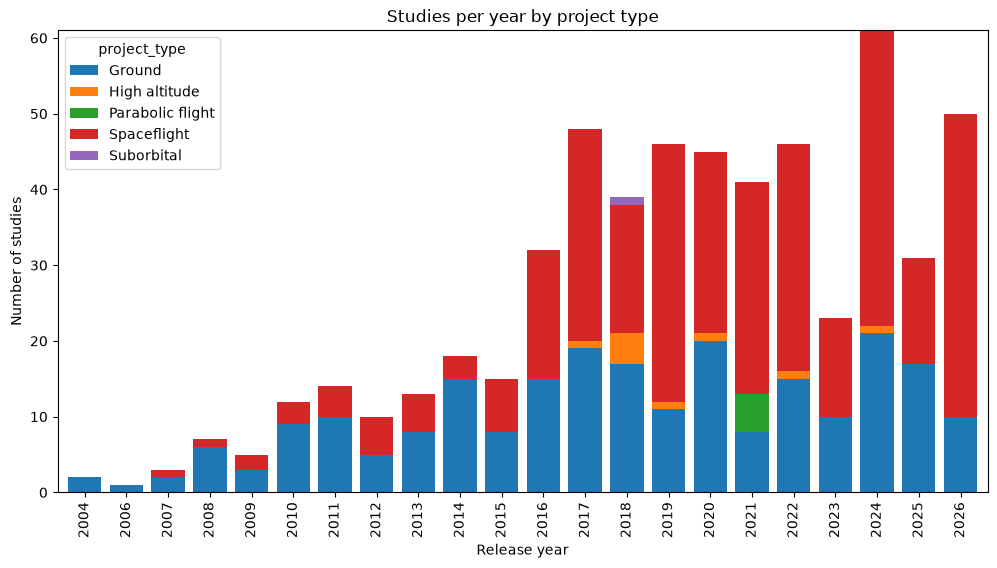

In [66]:
# bar chart of studies per year, colored by project type
year = df["release_date"].dt.year.astype("Int64").rename("year")

ax = (df.groupby([year, "project_type"]).size()
        .unstack(fill_value=0)
        .plot.bar(stacked=True, figsize=(12, 6), width=0.8))
ax.set_xlabel("Release year")
ax.set_ylabel("Number of studies")
ax.set_title("Studies per year by project type")


## Cleanup Mission Name column

In [67]:
df["Mission.Name"].value_counts()

Mission.Name
SpaceX-16                                 32
SpaceX-21                                 22
SpaceX-4                                  20
SpaceX-12                                 16
SpaceX-5                                  11
                                          ..
SpaceX-9  SpaceX-17  SpaceX-20             1
VSS Unity                                  1
Soyuz TMA-3 launch  Soyuz TMA-2 return     1
SpaceX-13  SpaceX-14                       1
NG-14                                      1
Name: count, Length: 87, dtype: int64

In [68]:
# missions are separated by 2+ spaces, same as organism
def split_missions(value):
    if pd.isna(value):
        return []
    parts = [p.strip().replace("_", "-") for p in re.split(r"\s{2,}", str(value))]
    return [p for p in parts if p]

df["missions"] = df["Mission.Name"].map(split_missions)

# mission name -> flight platform, first match wins
MISSION_RULES = [
    (r"Inspiration4", "Inspiration4"),   # free flyer, did not dock with the ISS
    (r"^(SpaceX|NG-|CRS|Orbital ATK|Expedition|ISS|Ax-)", "ISS"),
    (r"^Soyuz", "ISS"),                  # soyuz crew flights to the ISS
    (r"^STS-", "Space Shuttle"),
    (r"^Bion", "Bion-M1"),
    (r"Unity", "SpaceShipTwo"),
    (r"^UAVSAR$", "NASA Airborne Science Program"),
]

def mission_platform(mission):
    for pattern, platform in MISSION_RULES:
        if re.search(pattern, mission, flags=re.I):
            return platform
    return None

# missions that don't match any rule
unmatched = df["missions"].explode().dropna()
print("unmatched missions:", unmatched[unmatched.map(mission_platform).isna()].unique().tolist())

# only fill studies that don't have a flight platform yet
filled = 0
for idx in df.index[df["n_flight_platforms"] == 0]:
    platforms = sorted({mission_platform(m) for m in df.at[idx, "missions"]} - {None})
    if platforms:
        df.at[idx, "flight_platforms"] = platforms
        df.at[idx, "flight_program_source"] = "inferred from mission name"
        filled += 1

df["n_flight_platforms"] = df["flight_platforms"].str.len()
print("filled from mission name:", filled)
print("spaceflight studies still without a flight platform:",
      ((df["project_type"] == "Spaceflight") & (df["n_flight_platforms"] == 0)).sum())
print(df["flight_platforms"].explode().value_counts())


unmatched missions: ['PF2013', 'Foton-M4 and ISS Expedition 40/41']
filled from mission name: 22
spaceflight studies still without a flight platform: 10
flight_platforms
ISS                              275
Space Shuttle                     26
Inspiration4                       8
Bion-M1                            6
Parabolic flight                   3
NASA Airborne Science Program      2
SpaceShipTwo                       2
Soyuz                              1
TEXUS sounding rocket              1
Foton-M4                           1
Name: count, dtype: int64


## Cleanup assay and factor columns

In [ ]:
# these columns use 2+ spaces as separator too, and values are often repeated
def split_values(value, sep=r"\s{2,}"):
    if pd.isna(value):
        return []
    parts = [p.strip() for p in re.split(sep, str(value))]
    return [p for p in parts if p and p.lower() not in {"not applicable", "not available", "n/a", "others"}]

def fix_spelling(lists, fixes):
    """apply the fixes, then merge values that only differ in upper/lower case (keeps the most common spelling)"""
    lists = lists.map(lambda ps: [fixes.get(p, p) for p in ps])
    spelling = {}
    for value in lists.explode().dropna().value_counts().index:  # most common first
        spelling.setdefault(value.lower(), value)
    return lists.map(lambda ps: sorted({spelling[p.lower()] for p in ps}))

TECH_FIXES = {"microarray": "DNA microarray"}
FACTOR_FIXES = {
    "Space Flight": "Spaceflight",
    "Ionzing Radiation": "Ionizing Radiation", 
    "Radiation Ionzing": "Ionizing Radiation",
    "Simulated Microgravity": "Microgravity Simulation",
    "Tim": "Time",
}

df["assay_measurement"] = fix_spelling(df["Study Assay Measurement Type"].map(split_values), {})
# technology also has "16S and ITS"
df["assay_technology"] = fix_spelling(
    df["Study Assay Technology Type"].map(lambda v: split_values(v, sep=r"\s{2,}|\s+and\s+")), TECH_FIXES)
df["factors"] = fix_spelling(df["Study Factor Name"].map(split_values), FACTOR_FIXES)

for col in ["assay_measurement", "assay_technology", "factors"]:
    print(f"{col}: {df[col].explode().nunique()} unique values")
print(df["assay_technology"].explode().value_counts().head(15))


assay_measurement: 30 unique values
assay_technology: 44 unique values
factors: 134 unique values
assay_technology
RNA Sequencing (RNA-Seq)                       236
DNA microarray                                 161
mass spectrometry                               51
nucleotide sequencing                           38
single-cell RNA sequencing                      33
16S                                             30
Whole-Genome Shotgun Sequencing                 23
miRNA Sequencing                                18
Whole Genome Bisulfite Sequencing               14
spatial transcriptomics                         11
ITS                                              9
real time PCR                                    8
miRNA Microarray                                 5
Reduced-Representation Bisulfite Sequencing      5
Whole Transcriptome Bisulfite Sequencing         5
Name: count, dtype: int64


## Cleanup Material Type column

In [70]:
# controls aren't a material, drop them
CONTROLS = {"blank", "blank control", "solvent control", "positive control",
            "technical chip control", "reference rna"}
MATERIAL_FIXES = {
    "Cultured Cells": "Cells, Cultured",
    "Stool Sample": "Feces",
    "blood plasma": "Plasma",
}

materials = df["Material Type"].map(split_values).map(lambda ps: [p for p in ps if p.lower() not in CONTROLS])
df["material_types"] = fix_spelling(materials, MATERIAL_FIXES)

print("unique before:", df["Material Type"].map(split_values).explode().nunique(),
      "after:", df["material_types"].explode().nunique())
print("studies with no material type:", (df["material_types"].str.len() == 0).sum())
print(df["material_types"].explode().value_counts().head(15))


unique before: 211 after: 183
studies with no material type: 86
material_types
Cells               104
Whole Organism       28
Cells, Cultured      27
Liver                18
Spleen               12
Soleus               11
Feces                11
Seedlings            11
Vastus Lateralis     10
Plasma               10
Whole Blood           9
thymus                9
Brain                 8
Gastrocnemius         6
leaf                  6
Name: count, dtype: int64


In [72]:
# save the cleaned data to a new parquet file
df.to_parquet("../data/clean/studies_subset_t1_cleaned.parquet", index=False)
df

,Study Description,Study Title,Accession,organism,Material Type,Study Assay Measurement Type,Study Assay Technology Type,Study Factor Name,Mission.Name,Flight Program,...,flight_program_source,n_flight_platforms,project_type,project_type_source,release_date,missions,assay_measurement,assay_technology,factors,material_types
0,We report here the draft genome sequences of f...,Draft Genome Sequences of Acinetobacter and Ba...,OSD-263,Bacillus horneckiae Aranicola proteolyticu...,cells,genome sequencing,nucleotide sequencing,Sample Location,NaN,NaN,...,OSDR metadata,0,Ground,OSDR metadata,2017-12-20,[],[genome sequencing],[nucleotide sequencing],[Sample Location],[Cells]
1,The microbial tracking-1 (MT-1) investigation ...,Part two: ISS Enterobacteriales,OSD-311,Enterobacter bugandensis Kalamiella pierso...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,OSDR metadata,1,Spaceflight,OSDR metadata,2020-07-31,[],[genome sequencing],[nucleotide sequencing],"[Spaceflight, Strain]",[Cells]
2,The microbial tracking-1 (MT-1) investigation ...,ISS Enterobacteriales Genomes,OSD-302,Enterobacter bugandensis Pantoea brenneri ...,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,OSDR metadata,1,Spaceflight,OSDR metadata,2020-05-31,[],[genome sequencing],[nucleotide sequencing],"[Spaceflight, Strain]",[Cells]
3,Draft genome sequences of two Fusarium oxyspor...,Draft Genome Sequences of Two Fusarium oxyspor...,OSD-177,Fusarium oxysporum,Cells,genome sequencing,nucleotide sequencing,Spaceflight,SpaceX-3,Internation Space Station (ISS),...,OSDR metadata,1,Spaceflight,OSDR metadata,2018-03-30,[SpaceX-3],[genome sequencing],[nucleotide sequencing],[Spaceflight],[Cells]
4,Draft Genome sequences of Rhodotorula mucilagi...,Draft Genome sequences of Rhodotorula mucilagi...,OSD-293,Rhodotorula mucilaginosa,Cells,genome sequencing,nucleotide sequencing,Spaceflight Strain,NaN,Internation Space Station (ISS),...,OSDR metadata,1,Spaceflight,OSDR metadata,2020-05-15,[],[genome sequencing],[nucleotide sequencing],"[Spaceflight, Strain]",[Cells]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,Microphysiological systems provide the opportu...,Human skeletal muscle tissue chip autonomous p...,OSD-684,Homo sapiens,Myoblasts,transcription profiling,RNA Sequencing (RNA-Seq),Spaceflight Donor Age,SpaceX-21,International Space Station (ISS),...,OSDR metadata,1,Ground,OSDR metadata,2024-03-07,[SpaceX-21],[transcription profiling],[RNA Sequencing (RNA-Seq)],"[Donor Age, Spaceflight]",[Myoblasts]
573,The SpaceX Inspiration4 mission was a 3-day mi...,SpaceX Inspiration4 Plasma Profiling: Proteomi...,OSD-571,Homo sapiens,Plasma,protein expression profiling protein expre...,mass spectrometry mass spectrometry ma...,Spaceflight Time,SpaceX Inspiration4,NaN,...,inferred from mission name,1,Spaceflight,OSDR metadata,2024-05-14,[SpaceX Inspiration4],"[genome sequencing, metabolite profiling, prot...","[RNA Sequencing (RNA-Seq), mass spectrometry, ...","[Spaceflight, Time]",[Plasma]
574,In the Rodent Research Reference Mission (RRRM...,Bulk RNA sequencing and single nuclei transcri...,OSD-613,Mus musculus,Left cerebral hemisphere,transcription profiling Chromatin Accessib...,single-cell RNA sequencing single-cell ATA...,Spaceflight Age,SpaceX-18,International Space Station (ISS),...,OSDR metadata,1,Spaceflight,OSDR metadata,2023-08-01,[SpaceX-18],"[Chromatin Accessibility, transcription profil...","[RNA Sequencing (RNA-Seq), single-cell ATAC-se...","[Age, Spaceflight]",[Left cerebral hemisphere]
575,Translating fundamental biological discoveries...,Rodent Research-1 (RR1) NASA Validation Flight...,OSD-48,Mus musculus,Liver,transcription profiling protein expression...,RNA Sequencing (RNA-Seq) mass spectrometry...,Spaceflight Dissection Condition,SpaceX-4,NaN,...,inferred from mission name,1,Spaceflight,OSDR metadata,2015-12-15